# Topic 5 - Machine Learning (Part 1)

---
**Note: Content extracted from CM3005 course materials (available via Coursera)**

---

---

**Topic Learning Objectives**:
1. Understand machine learning fundamentals
2. Use scikit-learn (sklearn) to apply machine learning techniques
3. Understand feature engineering and model validation

---

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> 5.3 Selecting the Best Model </h2>
</div>

### 5.3.1 How Do We Improve Our Performance?

We can use a **holdout set** for **validation**
- **Cross-validation** using more trials
- More folds = more robust estimates

If our model is underperforming, how can we **improve** it?

Some options:
- A **more complex** model
- A **less complex** model
- More **training data**
- More/different **features**

It's not always obvious which approach to adopt!

### 5.3.2 The Bias-Variance Trade Off

Suppose we have two regression models:

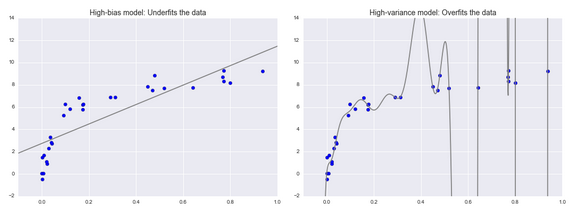

###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.03-hyperparameters-and-model-validation.html


Which is **better**?
- The first one (left) **underfits** the data -> high **bias**
- The second one (right) **overfits** the data -> high **variance**

Consider applying these models to unseen data. New data shown in red:

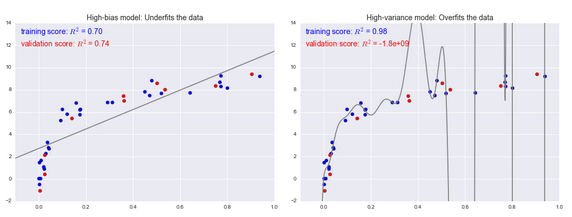

###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.03-hyperparameters-and-model-validation.html


$R^{2}$ is a measure of performance (a score of 1 is a perfect fit)
- **High bias** models show **similar performance** (train vs test)
- **High variance** models show very **different performance** (train vs test)

As a function of model complexity:
- **Performance** is invariably better on **training** data
- **High bias** models are poor predictors for both training and test
- **High variance** models overfit to the training data
- The optimium my be somewhere in between

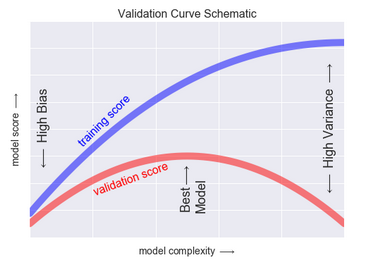

###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.03-hyperparameters-and-model-validation.html

### 5.3.3 Validation Curves

We will use a polynomial regression model with tunable parameter: degree

* First degree polynomial: $y = ax + b$
* Third degree polynomial: $y = ax^3 + bx^2 + cx + d$
* Fifth degree polynomial: $y = ax^5 + bx^4 + cx^3 + dx^2 + ex + f$


In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

# Return a pipeline with polynomial preprocessor and simple linear regression
def PolynomialRegression(degree=2, **kwargs):
    return make_pipeline(PolynomialFeatures(degree),
                         LinearRegression(**kwargs))

In [ ]:
# Create some data
import numpy as np

def make_data(N, err=1.0, rseed=1):
    # randomly sample the data
    rng = np.random.RandomState(rseed)
    X = rng.rand(N, 1) ** 2
    y = 10 - 1. / (X.ravel() + 0.1)  # .ravel() flattens an array into ID
    if err > 0:
        y += err * rng.randn(N)
    return X, y

X, y = make_data(40)

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn; seaborn.set()  # plot formatting

X_test = np.linspace(-0.1, 1.1, 500)[:, None]

plt.scatter(X.ravel(), y, color='black')
axis = plt.axis()
# Plot polynomials of degree 1, 3, 5
for degree in [1, 3, 5]:
    y_test = PolynomialRegression(degree).fit(X, y).predict(X_test)
    plt.plot(X_test.ravel(), y_test, label='degree={0}'.format(degree))
plt.xlim(-0.1, 1.0)
plt.ylim(-2, 12)
plt.legend(loc='best');

In [ ]:
from sklearn.model_selection import validation_curve
degree = np.arange(0, 21)
train_score, val_score = validation_curve(estimator=PolynomialRegression(), 
                                          X=X, y=y,
                                          param_name='polynomialfeatures__degree',
                                          param_range=degree, 
                                          cv=7)

plt.plot(degree, np.median(train_score, 1), color='blue', label='training score')
plt.plot(degree, np.median(val_score, 1), color='red', label='validation score')
plt.legend(loc='best')
plt.ylim(0, 1)
plt.xlabel('degree')
plt.ylabel('score');

In [ ]:
### Discuss wich polynomial degree generalizes best


In [ ]:
# Input the polynomial degree
degree = int(input("Enter the polynomial degree: "))

# Plot polynomial with given degree on its own
plt.scatter(X.ravel(), y)
lim = plt.axis()  # capture current axis limits
y_test = PolynomialRegression(degree).fit(X, y).predict(X_test)
plt.plot(X_test.ravel(), y_test)
plt.axis(lim);

### 5.3.4 Learning Curves

---

**Recap: What we've learnt so far...**

Bias-variance trade-off:
- **High bias** models can **underfit** the data
- **High variance** models can **overfit** the data

We can analyse **validation curves** to find the right level of **complexity**

---

In [ ]:
# Let's generate 200 data points (vs 40 originally)
X2, y2 = make_data(200)  
plt.scatter(X2.ravel(), y2);

In [ ]:
# Plot the validation curves using the newly generated 200 data points 
# (with original validation curves in dashed lines) 

degree = np.arange(21)

train_score2, val_score2 = validation_curve(estimator=PolynomialRegression(), 
                                          X=X2, y=y2,
                                          param_name='polynomialfeatures__degree',
                                          param_range=degree, 
                                          cv=7)

plt.plot(degree, np.median(train_score2, 1), color='blue', label='training score')
plt.plot(degree, np.median(val_score2, 1), color='red', label='validation score')
plt.plot(degree, np.median(train_score, 1), color='blue', alpha=0.3, linestyle='dashed')
plt.plot(degree, np.median(val_score, 1), color='red', alpha=0.3, linestyle='dashed')

plt.legend(loc='lower center')
plt.ylim(0, 1)
plt.xlabel('degree')
plt.ylabel('score');

#### But what about data?

Optimal model complexity will depend on the **size** of your **training data**

Validation curves depend on **both**:
- Model **complexity**
- **Size** of **training data**

How should model behaviour change as a function of training data size?
- Training scores should always be higher than validation scores
- A model of given complexity will **overfit** a relatively small data set
- A model of given complexity will **underfit** a relatively large data set

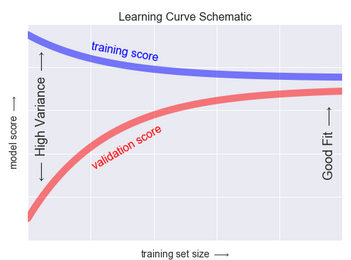

###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.03-hyperparameters-and-model-validation.html

In [ ]:
# Compare 2 models (polynomials of degree 2 and degree 9)

X, y = make_data(100)  # Generate 100 data points

from sklearn.model_selection import learning_curve

fig, ax = plt.subplots(1, 2, figsize=(16,6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for i, degree in enumerate([2, 9]):
    N, train_lc, val_lc = learning_curve(PolynomialRegression(degree),
                                         X, y, cv=7,
                                         train_sizes=np.linspace(0.1, 1, 20))
    ax[i].plot(N, np.mean(train_lc, 1), color='blue', label='training score')
    ax[i].plot(N, np.mean(val_lc, 1), color='red', label='validation score')
    ax[i].hlines(np.mean([train_lc[-1], val_lc[-1]]), N[0], N[-1], color='gray', linestyle='dashed')

    ax[i].set_ylim(0, 1)
    ax[i].set_xlim(N[0], N[-1])
    ax[i].set_xlabel('training size')
    ax[i].set_ylabel('score')
    ax[i].set_title('degree = {0}'.format(degree), size=14)
    ax[i].legend(loc='best')

plt.show()

In [ ]:
### Discuss your observations from these 2 charts (polynomials of degree 2 and 9)


### 5.3.5 Grid Search

How can we improve the performance of our models?
- We can analyse **validation curves** to find the right level of **complexity**
- We can analyse **learning curves** to explore the effect of **training set size**

Optimal performance may depend on **multiple parameters**

Is there some way to **automate** the process of model **optimization**?


In [ ]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

# Return a pipeline with a polynomial preprocessor and simple linear regression
def PolynomialRegression(degree=2, **kwargs):
    return make_pipeline(PolynomialFeatures(degree),
                         StandardScaler(),
                         LinearRegression(**kwargs))


In [ ]:
# Create some data
import numpy as np

def make_data(N, err=1.0, rseed=1):
    # randomly sample the data
    rng = np.random.RandomState(rseed)
    X = rng.rand(N, 1) ** 2
    y = 10 - 1. / (X.ravel() + 0.1)
    if err > 0:
        y += err * rng.randn(N)
    return X, y

# Make a data set
X, y = make_data(40)
# X, y = make_data (200)  # try larger dataset sizes


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {'polynomialfeatures__degree': np.arange(21),
              'linearregression__fit_intercept': [True, False]}

grid = GridSearchCV(PolynomialRegression(), param_grid, cv=7)

In [ ]:
grid.fit(X, y)

In [ ]:
grid.best_params_

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> 5.4 Feature Engineering </h2>
</div>

Up to now we've assumed that our data is in a readily **usable format**

**Real-world** data is rarely like this!

How can we **transform** information into usable data?


### 5.4.1 Categorical Features

Dealing with **non-numerical** data, e.g., **categorical**, **textual**, **image** data

Creating **derived** features

Dealing with **noisy** data, e.g., **missing values**


In [ ]:
data = [
    {'price': 850000, 'rooms': 4, 'neighborhood': 'Queen Anne'},
    {'price': 700000, 'rooms': 3, 'neighborhood': 'Fremont'},
    {'price': 650000, 'rooms': 3, 'neighborhood': 'Wallingford'},
    {'price': 600000, 'rooms': 2, 'neighborhood': 'Fremont'},
]

In [ ]:
# Not appropriate to turn the categories into numbers arbitrarily (shown below)
# Most machine learning techniques will place too much significance to these numbers

{'Queen Anne': 1, 'Fremont': 2, 'Wallingford': 3};

In [ ]:
# You can use one-hot encoding...
# DictVectorizer transforms lists of feature-value mappings (dictionaries) to vectors.
# Essentially, it performs one-hot encoding for categorical features in dictionaries.

from sklearn.feature_extraction import DictVectorizer
vec = DictVectorizer(sparse=False, dtype=int)
vec.fit_transform(data)

In [ ]:
vec.get_feature_names_out()

In [ ]:
# For DictVectorizer, setting sparse=True only stores the non-zero values
# Memory-efficient when most values are 0 (e.g., one-hot encoded data)

vec = DictVectorizer(sparse=True, dtype=int) 
vec.fit_transform(data)

### 5.4.2 Text Features

We can **vectorize categorical values** to transform them to **numerical data**.

What about **text**?
- Social media
- Documents
- Transcripts

How should we **encode** textual data?


In [ ]:
sample = ['the stars are not wanted now; put out every one',
          'pack up the moon and dismantle the sun',
          'pour away the ocean and sweep up the wood',
          'for nothing now can ever come to any good']

In [ ]:
# CountVectorizer converts a collection of text documents 
# into a bag-of-words numerical matrix

from sklearn.feature_extraction.text import CountVectorizer
vec = CountVectorizer()
X = vec.fit_transform(sample)
X

In [ ]:
import pandas as pd
pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out())

In [ ]:
# TfidfVectorizer applies TF-IDF (TF x IDF): 
#   TF (term frequency) = how often a word appears in a document
#   IDF (inverse document frequency) = how rare the word is across all documents
# Words that appear often in one document but rarely in other considered more important

from sklearn.feature_extraction.text import TfidfVectorizer
vec = TfidfVectorizer()
X = vec.fit_transform(sample)
pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out())

### 5.4.3 Feature Selection

---

**Recap: What we've learnt so far...**
- We can **vectorize categorical values** to transform them to **numerical** data
- We can **vectorize text data** to transform them to **numerical** data

---

#### How do we choose the 'best' features?

Sometimes the choice is not so simple

Example: Building a spam classifier
- Does the email contain the **word** 'Viagra' or 'Lottery'
- **Frequency** of **certain characters**, e.g., ! or $
- **Email address** of the sender

How do we choose?
- Experience
- Domain expertise
- Experimentation

Sometimes features can interact in unexpected ways, e.g., house prices
- Location
- Size

We may need to consider **combined** features, or mathematically **derived** features

In [ ]:
# Create some non-linear data points
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

x = np.array([1, 2, 3, 4, 5])
y = np.array([4, 2, 1, 3, 7])
plt.scatter(x, y);

In [ ]:
# Attempt to fit a straight line
from sklearn.linear_model import LinearRegression
X = x[:, np.newaxis]
model = LinearRegression().fit(X, y)
yfit = model.predict(X)
plt.scatter(x, y)
plt.plot(x, yfit);

In [ ]:
# Add an extra feature representing x^2
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=2, include_bias=False)
X2 = poly.fit_transform(X)
print(X2)

In [ ]:
# Now the predictions are much closer
model = LinearRegression().fit(X2, y)
yfit = model.predict(X2)
plt.scatter(x, y)
plt.plot(x, yfit);

### 5.4.4 Imputation of Missing Data

#### Dealing with Missing Data

Real world data is rarely **clean** or **homogeneous**

**Missing** data conventions
- Use a **mask**, e.g., a Boolean flag
- Use a **sentinel value**, e.g., -9999

Pandas uses:
- **None** (a Python **object**)
- **NaN** (a **float64**)


#### Dealing with Null Values

**Detection**: 
- isnull(), notnull() return a **Boolean mask** over the data

**Drop** null values: 
- dropna() **removes** NA values (`how` + `thresh` params control # of nulls to allow)

**Fill** null values: 
- fillna() **replaces** NA values (e.g., with single value, previous value, etc.)

In [ ]:
# Create a 2D array with missing values
import numpy as np
from numpy import nan
X = np.array([[ nan, 0,   3 ],
              [ 3,   7,   9 ],
              [ 3,   5,   2 ],
              [ 4,   nan, 6 ],
              [ 8,   8,   1 ]])
y = np.array([14, 16, -1, 8, -5])

In [ ]:
# Fit a linear regression model to the data
# Note: Code throws an error
from sklearn.linear_model import LinearRegression
model = LinearRegression().fit(X, y)
model.predict(X)

In [ ]:
from sklearn.impute import SimpleImputer
imp = SimpleImputer(strategy='most_frequent')  # Other strategy options: 'mean', 'median'
X2 = imp.fit_transform(X)
X2

In [ ]:
# Fit a linear regression model to the data
from sklearn.linear_model import LinearRegression
model = LinearRegression().fit(X2, y)
model.predict(X2)

In [ ]:
model.score(X2, y)

### 5.4.5 Feature Pipelines

A common processing pipeline
1. Impute missing values (e.g., using median)
2. Transform features (e.g., using a polynomial)
3. Fit a linear regression

In [ ]:
# Create a 2D array with missing values
import numpy as np
from numpy import nan
X = np.array([[ nan, 0,   3 ],
              [ 3,   7,   9 ],
              [ 3,   5,   2 ],
              [ 4,   nan, 6 ],
              [ 8,   8,   1 ]])
y = np.array([14, 16, -1, 8, -5])

In [ ]:
# Impute the missing values using the mean
from sklearn.impute import SimpleImputer
imp = SimpleImputer(strategy='mean')
Ximp = imp.fit_transform(X)
Ximp

In [ ]:
# Transform the feature space using a polynomial, degree = 3
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=3)
Ximp_trans = poly.fit_transform(Ximp)

In [ ]:
# Fit a linear regression model
from sklearn.linear_model import LinearRegression
model = LinearRegression().fit(Ximp_trans, y)
yfit = model.predict(Ximp_trans)

In [ ]:
# Create some test data
Xtest = np.array([[ nan, 1,   4  ],
                  [ 4,   8,   10 ],
                  [ 4,   6,   3  ],
                  [ 5,   nan, 7  ],
                  [ 9,   9,   2  ]])
ytest = np.array([15, 17, 0, 9, -4])

In [ ]:
# Impute the missing values
# Xtest_imp = imp.fit_transform(Xtest)  # should not re-fit for test data
Xtest_imp = imp.transform(Xtest)
Xtest_imp

In [ ]:
# Transform the feature space
# Xtest_imp_trans = poly.fit_transform(Xtest_imp)  # should not re-fit for test data
Xtest_imp_trans = poly.transform(Xtest_imp)

In [ ]:
preds = model.predict(Xtest_imp_trans)
print(preds)

In [ ]:
model.score(Xtest_imp_trans, ytest)

In [ ]:
# Create a pipeline to replace the individual steps used above
# This can help streamline the process and avoid error-prone steps

# from sklearn.pipeline import make_pipeline
# from sklearn.preprocessing import PolynomialFeatures
# from sklearn.linear_model import LinearRegression
model = make_pipeline(SimpleImputer(strategy='mean'),
                      PolynomialFeatures(degree=3),
                      LinearRegression())

In [ ]:
model.fit(X, y)  # X with missing values
preds = model.predict(Xtest)
print(preds)

In [ ]:
model.score(Xtest, ytest)

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> Looking Ahead & Key Reminders </h2>
</div>

**Looking Ahead: More advanced techniques will be covered in Topic 9 of the course**
- Support vector machines (SVM)
- Decision trees
- Random forests
- kMeans clustering
- ... and more!

**Reminder: Mid-Term Coursework Submission**

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> References & Notes </h2>
</div>

**References**
- VanderPlas, J. (2016). *Python data science handbook: Essential tools for working with data*. O’Reilly Media. https://jakevdp.github.io/PythonDataScienceHandbook/

**Notes**
- Excerpts from Python Data Science Handbook by Jake VanderPlas are used. The text is released under the CC-BY-NC-ND license, and the code examples are released under the MIT license.